In [2]:
"""
SBI (NPE) posterior inference for log(alpha) and rho, trained on the same simulations as the CNN regressor
(real OrthoMaM trees, LG model, window 250). Simulations are loaded from the saved npz files.
"""
import math
import numpy as np
import torch
import torch.nn as nn
from sbi.utils import BoxUniform
from sbi.inference import NPE
from sbi.neural_nets import posterior_nn

import prior

ALPHA_RANGE = (0.1, 3.0)  # log-uniform in the simulations
TRAIN_PATH = "../sims_amino_alphaprior_w250_n20000_train.npz"
TEST_PATH = "../sims_amino_alphaprior_w250_n500_test.npz"


def load_sims(path):
    """Return x = [flattened CNN features, 2 scalars] and theta = [log(alpha), rho]."""
    d = np.load(path)
    features = torch.from_numpy(d["features"]).float()
    scalars = torch.from_numpy(d["scalars"]).float()
    theta = torch.stack([torch.from_numpy(d["alpha"]).float().log(), torch.from_numpy(d["rho"]).float()], dim=1)
    x = torch.cat([features.flatten(1), scalars], dim=1)
    return x, theta, features.shape[-1]


x_train, theta_train, seq_len = load_sims(TRAIN_PATH)
x_test, theta_test, _ = load_sims(TEST_PATH)
print(x_train.shape, theta_train.shape, x_test.shape)

prior_dist = BoxUniform(
    low=torch.tensor([math.log(ALPHA_RANGE[0]), prior.RHO_RANGE[0]]),
    high=torch.tensor([math.log(ALPHA_RANGE[1]), prior.RHO_RANGE[1]]),
)


class CNNScalarEmbedding(nn.Module):
    """CNN on the 2 x seq_len features (global average pool) concatenated with the 2 scalars -> 130 dims."""

    def __init__(self, seq_len, n_scalars=2):
        super().__init__()
        self.seq_len = seq_len
        self.n_scalars = n_scalars
        self.net = nn.Sequential(
            nn.Conv1d(2, 32, kernel_size=5, padding=2), nn.ReLU(),
            nn.Conv1d(32, 64, kernel_size=5, padding=2), nn.ReLU(),
            nn.Conv1d(64, 128, kernel_size=5, padding=2), nn.ReLU(),
        )

    def forward(self, x):
        features = x[:, :-self.n_scalars].reshape(-1, 2, self.seq_len)
        scalars = x[:, -self.n_scalars:]
        return torch.cat([self.net(features).mean(dim=-1), scalars], dim=1)

torch.Size([20000, 502]) torch.Size([20000, 2]) torch.Size([500, 502])


In [3]:
neural_posterior = posterior_nn(model="maf", embedding_net=CNNScalarEmbedding(seq_len))
inference = NPE(prior=prior_dist, density_estimator=neural_posterior)
inference.append_simulations(theta_train, x_train).train()
posterior = inference.build_posterior()

/home/elyalab/Dev/failed_syncs/rateAutoCorrelation/.venv/lib/python3.10/site-packages/sbi/inference/trainers/npe/npe_base.py:196: UserWarning: Data has constant values in dimension(s) [499]. These dimensions carry no information and will be mapped to zero after z-scoring. Consider removing constant features from your data.
  warn_if_invalid_for_zscoring(x)


 Neural network successfully converged after 182 epochs.

In [6]:
import pickle
with open("posterior_amino_alphaprior.pkl", "wb") as f:
    pickle.dump(posterior, f)

In [4]:
# posterior median per held-out test simulation
inferred = []
for x in x_test:
    samples = posterior.sample((5000,), x=x.unsqueeze(0), show_progress_bars=False)
    inferred.append(samples.median(dim=0).values)
inferred = torch.stack(inferred)

for i, name in enumerate(["log(alpha)", "rho"]):
    true, pred = theta_test[:, i], inferred[:, i]
    r2 = 1 - ((pred - true) ** 2).sum() / ((true - true.mean()) ** 2).sum()
    rmse = ((pred - true) ** 2).mean().sqrt()
    print(f"{name}: R^2={r2:.4f}, RMSE={rmse:.4f}")

log(alpha): R^2=0.9030, RMSE=0.3076
rho: R^2=0.7726, RMSE=0.1289


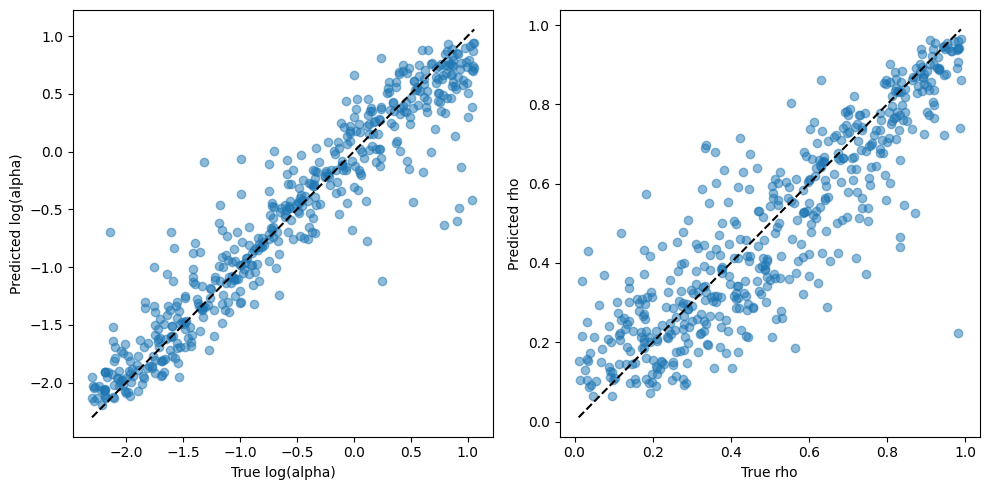

In [5]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for i, (ax, name) in enumerate(zip(axes, ["log(alpha)", "rho"])):
    ax.scatter(theta_test[:, i].numpy(), inferred[:, i].numpy(), alpha=0.5)
    lims = [theta_test[:, i].min().item(), theta_test[:, i].max().item()]
    ax.plot(lims, lims, "k--")
    ax.set_xlabel(f"True {name}")
    ax.set_ylabel(f"Predicted {name}")
plt.tight_layout()
plt.show()

In [7]:
class RhoRegressor(nn.Module):
    def __init__(self, n_scalars=2):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(2, 32, 5, padding=2), nn.ReLU(),
            nn.Conv1d(32, 64, 5, padding=2), nn.ReLU(),
            nn.Conv1d(64, 128, 5, padding=2), nn.ReLU(),
        )
        self.head = nn.Sequential(nn.Linear(128 + n_scalars, 64), nn.ReLU(), nn.Linear(64, 1))

    def forward(self, x, scalars):
        return self.head(torch.cat([self.cnn(x).mean(dim=-1), scalars], dim=1)).squeeze(-1)

reg = RhoRegressor()
reg.load_state_dict(torch.load("../rho_regressor_amino_alphaprior_w250.pt", map_location="cpu"))
reg.eval()

d = np.load(TEST_PATH)
rho_true = d["rho"]
with torch.no_grad():
    rho_cnn = reg(torch.from_numpy(d["features"]).float(), torch.from_numpy(d["scalars"]).float()).numpy()

rmse = np.sqrt(np.mean((rho_cnn - rho_true) ** 2))
r2 = 1 - np.sum((rho_cnn - rho_true) ** 2) / np.sum((rho_true - rho_true.mean()) ** 2)
print(f"rho CNN-only: R^2={r2:.4f}, RMSE={rmse:.4f}")

rho CNN-only: R^2=0.7528, RMSE=0.1345


In [8]:
import sys; sys.path.append("../common")  # adjust to where common/ is
from cnn_embedding import CNNScalarEmbedding as NewEmb

for m in posterior.posterior_estimator.modules():
    if type(m).__name__ == "CNNScalarEmbedding":
        m.__class__ = NewEmb

with open("posterior_amino_alphaprior.pkl", "wb") as f:
    pickle.dump(posterior, f)